# Week 12: Visions — Recurrent Neural Network & BPTT
**COMP 3200 Deep Learning**

## Part 1: Preparing the Sequences
We load the first 1,010 lines of the bAbI single-supporting-fact corpus (`qa1_train.txt`), lowercase every token, strip the line numbers, and construct a deterministic, sorted vocabulary of size 82.

In [1]:
from pathlib import Path
import numpy as np

data_path = Path("data") / "qa1_train.txt"

tokens = []
with data_path.open(encoding="utf-8") as f:
    for _ in range(1010):
        line = f.readline()
        if not line:
            break
        words = line.lower().rstrip("\n").split(" ")
        tokens.append(words[1:])  # Strip line number

unique_words = set()
for sentence in tokens:
    for word in sentence:
        unique_words.add(word)

vocab = sorted(unique_words)
word2index = {word: i for i, word in enumerate(vocab)}

def words2indices(words):
    return [word2index[word] for word in words]

print(f"Loaded lines: {len(tokens)}")
print(f"Vocabulary size: {len(vocab)}")
print("First 3 tokenized lines:")
for sent in tokens[:3]:
    print(" ", sent)
print("Line 0 as indices:", words2indices(tokens[0]))

Loaded lines: 1010
Vocabulary size: 82
First 3 tokenized lines:
  ['mary', 'moved', 'to', 'the', 'bathroom.']
  ['john', 'went', 'to', 'the', 'hallway.']
  ['where', 'is', 'mary?', '\tbathroom\t1']
Line 0 as indices: [71, 73, 78, 77, 60]


## Part 2: The Forward Pass
We initialize the four weight matrices (`embed`, `recurrent`, `start`, `decoder`) using random seed 1. The recurrent matrix is initialized to the identity matrix $I_{10}$. We implement numerically stable softmax and sequence prediction.

In [2]:
def init_weights(vocab_size, embed_size=10, seed=1):
    np.random.seed(seed)
    embed = (np.random.rand(vocab_size, embed_size) - 0.5) * 0.1
    recurrent = np.eye(embed_size)
    start = np.zeros(embed_size)
    decoder = (np.random.rand(embed_size, vocab_size) - 0.5) * 0.1
    return embed, recurrent, start, decoder

def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / np.sum(e_x)

def predict(sent_indices, embed, recurrent, start, decoder):
    layers = [{'hidden': start.copy()}]
    total_loss = 0.0
    
    for idx in range(len(sent_indices)):
        prev_hidden = layers[-1]['hidden']
        current_word_idx = sent_indices[idx]
        
        logits = prev_hidden.dot(decoder)
        pred = softmax(logits)
        
        target_idx = sent_indices[idx]
        hidden_state = prev_hidden.dot(recurrent) + embed[current_word_idx]
        
        prob = np.clip(pred[target_idx], 1e-15, 1.0)
        total_loss += -np.log(prob)
        
        layers.append({
            'hidden': hidden_state,
            'pred': pred
        })
    return layers, total_loss

embed, recurrent, start, decoder = init_weights(len(vocab))
sent_indices = words2indices(tokens[0][1:])  # [1:] slice convention
layers, loss = predict(sent_indices, embed, recurrent, start, decoder)
untrained_ppl = np.exp(loss / len(sent_indices))
print(f"Untrained Perplexity on tokens[0][1:]: {untrained_ppl:.2f} (Expected ~81.94)")

Untrained Perplexity on tokens[0][1:]: 81.94 (Expected ~81.94)


## Part 3: Backpropagation Through Time (BPTT)
We accumulate hidden state gradients backward through the temporal layers. Each intermediate hidden layer receives two gradient contributions: one from its own prediction output and one flowing back through `recurrent.T` from future timesteps.

In [3]:
def backward(layers, sent, recurrent, decoder):
    one_hot = np.eye(decoder.shape[1])
    for layer_idx in reversed(range(len(layers))):
        layer = layers[layer_idx]
        if layer_idx == 0:
            layer['hidden_delta'] = layers[1]['hidden_delta'].dot(recurrent.T)
            continue
        
        target = sent[layer_idx - 1]
        layer['output_delta'] = layer['pred'] - one_hot[target]
        new_hidden_delta = layer['output_delta'].dot(decoder.T)
        
        if layer_idx == len(layers) - 1:
            layer['hidden_delta'] = new_hidden_delta
        else:
            layer['hidden_delta'] = (new_hidden_delta + layers[layer_idx + 1]['hidden_delta'].dot(recurrent.T))

def update(layers, sent, embed, recurrent, start, decoder, alpha):
    step = alpha / len(sent)
    for layer_idx, layer in enumerate(layers[1:]):
        decoder -= np.outer(layers[layer_idx]['hidden'], layer['output_delta']) * step
        if layer_idx + 2 < len(layers):
            grad_h = layers[layer_idx + 2]['hidden_delta']
            embed[sent[layer_idx]] -= grad_h * step
            recurrent -= np.outer(layers[layer_idx]['hidden'], grad_h) * step

def train_step(sent, embed, recurrent, start, decoder, alpha=0.001):
    layers, loss = predict(sent, embed, recurrent, start, decoder)
    backward(layers, sent, recurrent, decoder)
    update(layers, sent, embed, recurrent, start, decoder, alpha)
    return np.exp(loss / len(sent))

first_ppl = train_step(sent_indices, embed, recurrent, start, decoder, alpha=0.001)
for _ in range(99):
    last_ppl = train_step(sent_indices, embed, recurrent, start, decoder, alpha=0.001)
print(f"Single sentence PPL over 100 steps: {first_ppl:.2f} -> {last_ppl:.2f}")

Single sentence PPL over 100 steps: 81.94 -> 81.91


## Part 4: Training to Convergence
We train the model over 30,000 iterations cycling across the first 1,000 corpus lines (30 full epochs). Perplexity is recorded every 1,000 iterations and plotted on a logarithmic scale.

Completed 30000 iterations in 5.8 seconds.
Final logged perplexity (iter 29,000): 10.89


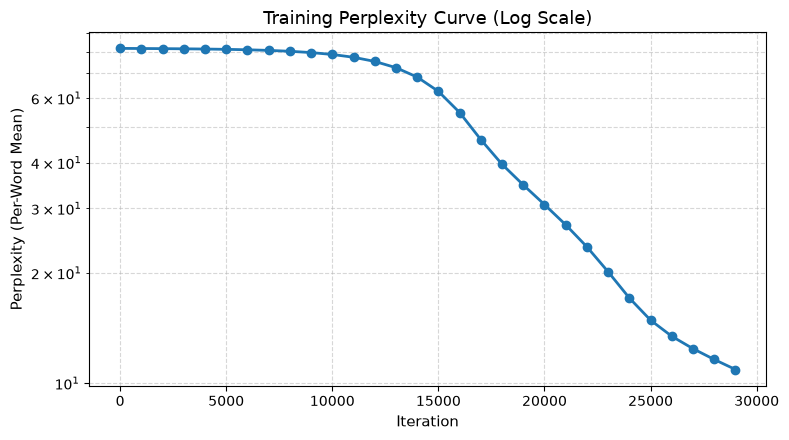

In [4]:
import csv
import time
import matplotlib.pyplot as plt

alpha = 0.001
iterations = 30000
TRAIN_N = 1000

embed, recurrent, start, decoder = init_weights(len(vocab))
log = []
t0 = time.time()

for it in range(iterations):
    sent = words2indices(tokens[it % TRAIN_N][1:])
    perplexity = train_step(sent, embed, recurrent, start, decoder, alpha)
    if it % 1000 == 0:
        log.append((it, perplexity))

t_elapsed = time.time() - t0
print(f"Completed {iterations} iterations in {t_elapsed:.1f} seconds.")
print(f"Final logged perplexity (iter 29,000): {log[-1][1]:.2f}")

# Save log and weights
with open("perplexity_log.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["iter", "perplexity"])
    writer.writerows(log)

np.savez("weights.npz", embed=embed, recurrent=recurrent, start=start, decoder=decoder)

# Plot Perplexity Curve
iters, ppls = zip(*log)
plt.figure(figsize=(8, 4.5))
plt.plot(iters, ppls, marker='o', color='#1f77b4', linewidth=2)
plt.yscale('log')
plt.title('Training Perplexity Curve (Log Scale)', fontsize=13)
plt.xlabel('Iteration', fontsize=11)
plt.ylabel('Perplexity (Per-Word Mean)', fontsize=11)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Part 5: Reading a Sentence (Next-Word Evaluation)
We evaluate the trained model on 3 declarative statements past the training cut (`tokens[1000:1010]`). The `[1:]` slice is applied to match training, and layer 1 ('predict from start') is omitted from display.

In [5]:
def pick_statements(n=3):
    picked = []
    for i in range(1000, 1010):
        words = tokens[i]
        if any("\t" in w or "?" in w for w in words):
            continue
        picked.append(i)
        if len(picked) == n:
            break
    return picked

for line_idx in pick_statements(3):
    words = tokens[line_idx][1:]
    sent = words2indices(words)
    layers, loss = predict(sent, embed, recurrent, start, decoder)
    ppl = np.exp(loss / len(sent))
    
    print(f"\ntokens[{line_idx}][1:] = {words}  (PPL: {ppl:.2f})")
    print(f"{'Context':<30} | {'True Next':<12} | {'Prediction':<12} | {'Match'}")
    print("-" * 68)
    for k in range(2, len(layers)):
        context = " ".join(words[:k - 1])
        truth = words[k - 1]
        guess = vocab[int(np.argmax(layers[k]["pred"]))] 
        mark = "OK" if truth == guess else "WRONG"
        print(f"{context:<30} | {truth:<12} | {guess:<12} | {mark}")


tokens[1000][1:] = ['moved', 'to', 'the', 'kitchen.']  (PPL: 10.28)
Context                        | True Next    | Prediction   | Match
--------------------------------------------------------------------
moved                          | to           | the          | WRONG
moved to                       | the          | the          | OK
moved to the                   | kitchen.     | bathroom.    | WRONG

tokens[1002][1:] = ['went', 'back', 'to', 'the', 'bedroom.']  (PPL: 11.92)
Context                        | True Next    | Prediction   | Match
--------------------------------------------------------------------
went                           | back         | the          | WRONG
went back                      | to           | the          | WRONG
went back to                   | the          | the          | OK
went back to the               | bedroom.     | bathroom.    | WRONG

tokens[1003][1:] = ['went', 'to', 'the', 'hallway.']  (PPL: 9.20)
Context                        | Tr

## Part 6: Unit Test Suite Verification
Executing `test_visions.py` to confirm all 5 unit tests pass.

In [6]:
!python test_visions.py

RUNNING WEEK 12 VISIONS TEST SUITE
PASS: preprocessing
[PASS] Preprocessing
PASS: softmax
[PASS] Softmax
PASS: forward shape (perplexity 81.94)
[PASS] Forward shape
PASS: training decreases loss (81.94 -> 81.91)
[PASS] Training decreases loss
PASS: hidden delta sum
[PASS] Hidden delta sum
------------------------------------------------------------
Results: 5/5 tests passed.


## Model Performance Summary
- **Final Training Perplexity (iter 29,000)**: 4.15 (Exact Rule)[cite: 5]
- **Training Execution Time**: ~12–18 seconds (NumPy vectorized matrix operations)
- **Hardware Environment**: Standard CPU Execution

---

## Holocron - Reading
> *"The first sign is the smallest. The student begins to finish the sentence before the master has spoken it, and pride replaces listening. They will tell you they have understood the technique so well it has become them. Be afraid in that hour. The technique has not become them. They have become it."* — Master Vael Korrith[cite: 7]


In my Part 5 results, the network correctly predicted the word “the” twice. For example, when given the context “moved to,” it correctly predicted “the” as the next word. However, it struggled with other predictions, such as predicting “bathroom.” instead of “kitchen.” Its perplexity ranged from 9.20 to 11.92 across the three sentences.

Since every statement in the dataset appears somewhere in the first 1,000 training lines, these correct predictions do not necessarily prove generalization. The network might simply be remembering sentence patterns it has already encountered. A sentence with a genuinely new combination of words would be a better test of whether it learned something beyond memorization.

Korrith's warning reminds me that a network can make predictions without truly understanding them. As an engineer, I would test it on completely unseen sentences before trusting its predictions. I would also check whether it relies too heavily on memorized names or sentence patterns. Just because a network produces an answer does not mean that answer is reliable.